# CSC 4233 NLP Mid-Term Project: SMS Spam Detection (Section B, Group G09)

**Problem:** Decide whether an English SMS is **spam** or **ham** (a normal message). A phone company could use this to block scam and phishing texts automatically.

**Dataset:** SMS Spam Collection (UCI), 5,574 labelled English messages, 2 classes (4,827 ham / 747 spam). Licence: Creative Commons Attribution 4.0 (CC BY 4.0), so academic use is allowed. Source: Almeida, Gómez Hidalgo & Yamakami (2011), *Contributions to the study of SMS spam filtering*, ACM DocEng. https://archive.ics.uci.edu/dataset/228/sms+spam+collection

**Plan:** Setup → Load and split → Preprocessing and ablation → EDA → Representations → Models → Final test evaluation → Error analysis → Conclusions. Only Weeks 1-5 techniques are used (regex, BoW, TF-IDF, Word2Vec, Naive Bayes, Logistic Regression), no transformers.

## 1. Setup
**Title: Install and import libraries**

Installs `gensim` (needed for Word2Vec, may not be preinstalled on Colab), imports everything we use, downloads the NLTK stop-word list, and fixes the random seed so results are reproducible.

In [1]:
!pip install -q gensim

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

nltk.download('stopwords', quiet=True)
SEED = 42                 # fixed seed used everywhere
np.random.seed(SEED)

## 2. Load the data and split it (70 / 15 / 15)
**Title: Load the CSV from GitHub and make a stratified split**

The dataset is read straight from a public GitHub link (no uploads needed). We then split it into 70% train, 15% validation and 15% test. `stratify` keeps the 87% / 13% ham/spam ratio in every part, and the fixed seed makes the split repeatable. We tune on validation only and use the test set once at the end.

In [2]:
URL = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/sms_spam.csv'
df = pd.read_csv(URL).rename(columns={'type': 'label', 'text': 'message'})
print('Rows:', len(df))
print(df['label'].value_counts())

# 70% train, 15% validation, 15% test (stratified)
train_val, test = train_test_split(df, test_size=0.15, stratify=df['label'], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.15 / 0.85, stratify=train_val['label'], random_state=SEED)
train, val, test = train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)
print('Train / Validation / Test sizes:', len(train), len(val), len(test))

Rows: 5574
label
ham     4827
spam     747
Name: count, dtype: int64
Train / Validation / Test sizes: 3901 836 837


## 3. Preprocessing pipeline and ablation
**Title: Reusable `preprocess()` function**

One function cleans a message. Each step and why we use it:
1. **Lowercase** (case folding): "FREE" and "free" should count as the same word.
2. **Remove HTML tags/entities** (e.g. `&lt;#&gt;`): web-page leftovers carry no meaning.
3. **Remove URLs**: every link is different, so the exact text does not generalise.
4. **Remove numbers**: phone numbers and prices are almost always unique.
5. **Remove punctuation, symbols and emojis** (keep only letters a-z): they are noise for bag-of-words models.
6. **Tokenise** with `split()`: after cleaning, words are separated by spaces.
7. **Stop-word removal** (optional): drops very common words such as "the".
8. **Stemming** (optional): reduces "winning", "wins" to "win" so word forms are counted together.

Steps 7 and 8 are switches, so the next cell can test whether they actually help.

In [3]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text, remove_stop=True, use_stem=True):
    text = text.lower()                              # 1. case folding
    text = re.sub(r'<.*?>|&\w+;', ' ', text)          # 2. HTML tags and entities
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)  # 3. URLs
    text = re.sub(r'\d+', ' ', text)                  # 4. numbers
    text = re.sub(r'[^a-z\s]', ' ', text)             # 5. punctuation, symbols, emojis
    words = text.split()                             # 6. tokenise
    if remove_stop:
        words = [w for w in words if w not in stop_words]   # 7. stop words
    if use_stem:
        words = [stemmer.stem(w) for w in words]            # 8. stemming
    return ' '.join(words)

print(preprocess('WINNER!! Call 09061209465 now & claim your FREE prize at http://win.com <b>today</b> :)'))

winner call claim free prize today


**Title: Ablation study (which pipeline variant is best?)**

We try all 4 combinations of stop-word removal and stemming. Each variant is trained on the **training** set and scored on the **validation** set (macro-F1) with two simple models: Naive Bayes + BoW and Logistic Regression + TF-IDF. The variant with the best average score is used for the rest of the notebook.

In [4]:
def quick_f1(vectorizer, model, train_text, val_text):
    # fit on train only, score on validation
    model.fit(vectorizer.fit_transform(train_text), train['label'])
    return f1_score(val['label'], model.predict(vectorizer.transform(val_text)), average='macro')

ablation = []
for remove_stop in [False, True]:
    for use_stem in [False, True]:
        tr = train['message'].apply(preprocess, remove_stop=remove_stop, use_stem=use_stem)
        va = val['message'].apply(preprocess, remove_stop=remove_stop, use_stem=use_stem)
        ablation.append({
            'stop-word removal': remove_stop,
            'stemming': use_stem,
            'NB + BoW macro-F1': quick_f1(CountVectorizer(), MultinomialNB(), tr, va),
            'LR + TF-IDF macro-F1': quick_f1(TfidfVectorizer(), LogisticRegression(C=10, max_iter=1000), tr, va)})
ablation = pd.DataFrame(ablation)
ablation['mean macro-F1'] = ablation[['NB + BoW macro-F1', 'LR + TF-IDF macro-F1']].mean(axis=1)
display(ablation.round(4))

best = ablation.loc[ablation['mean macro-F1'].idxmax()]
REMOVE_STOP, USE_STEM = bool(best['stop-word removal']), bool(best['stemming'])
print(f'Chosen pipeline -> stop-word removal: {REMOVE_STOP}, stemming: {USE_STEM}')

# apply the chosen pipeline to all three parts
for part in (train, val, test):
    part['clean'] = part['message'].apply(preprocess, remove_stop=REMOVE_STOP, use_stem=USE_STEM)

,stop-word removal,stemming,NB + BoW macro-F1,LR + TF-IDF macro-F1,mean macro-F1
0,False,False,0.9715,0.9738,0.9727
1,False,True,0.9642,0.9818,0.9730
2,True,False,0.9591,0.9653,0.9622
3,True,True,0.9570,0.9628,0.9599


Chosen pipeline -> stop-word removal: False, stemming: True


## 4. Exploratory data analysis (EDA)
**Title: Class balance and message-length statistics**

We look at the **training set** only. First the class counts (is the data imbalanced?) and the number of words per message **before** and **after** preprocessing, for each class. Then two figures: class distribution and message length per class.

label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


words before                 words after                
              mean median min  max        mean median min  max
label                                                         
ham           14.1   11.0   1  171        14.3   11.0   0  190
spam          23.8   25.0   2   35        22.4   23.0   2   36

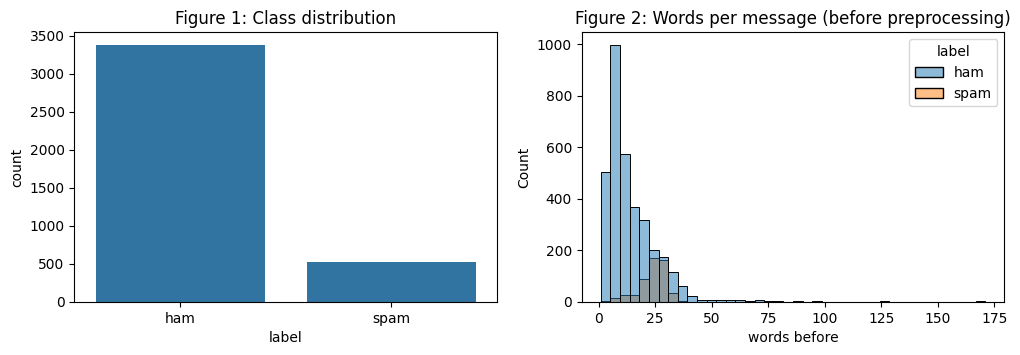

Figure 1: ham is about 87% and spam about 13%, so the data is imbalanced; accuracy alone would be misleading.
Figure 2: spam messages are longer and more tightly clustered than ham, so length is a useful signal.


In [5]:
print(train['label'].value_counts(normalize=True).round(3))
lengths = pd.DataFrame({
    'label': train['label'],
    'words before': train['message'].str.split().str.len(),
    'words after': train['clean'].str.split().str.len()})
display(lengths.groupby('label').agg(['mean', 'median', 'min', 'max']).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.countplot(x='label', data=train, ax=axes[0])
axes[0].set_title('Figure 1: Class distribution')
sns.histplot(data=lengths, x='words before', hue='label', bins=40, ax=axes[1])
axes[1].set_title('Figure 2: Words per message (before preprocessing)')
plt.show()
print('Figure 1: ham is about 87% and spam about 13%, so the data is imbalanced; accuracy alone would be misleading.')
print('Figure 2: spam messages are longer and more tightly clustered than ham, so length is a useful signal.')

**Title: Most frequent words per class (before vs after preprocessing)**

"Before" means raw lowercase words from the original text. "After" means the words left after our chosen pipeline. Because the chosen pipeline may keep stop words, a third figure (for viewing only, not used by any model) also hides stop words so the content words are visible. Each figure shows the top 10 words for ham (left) and spam (right).

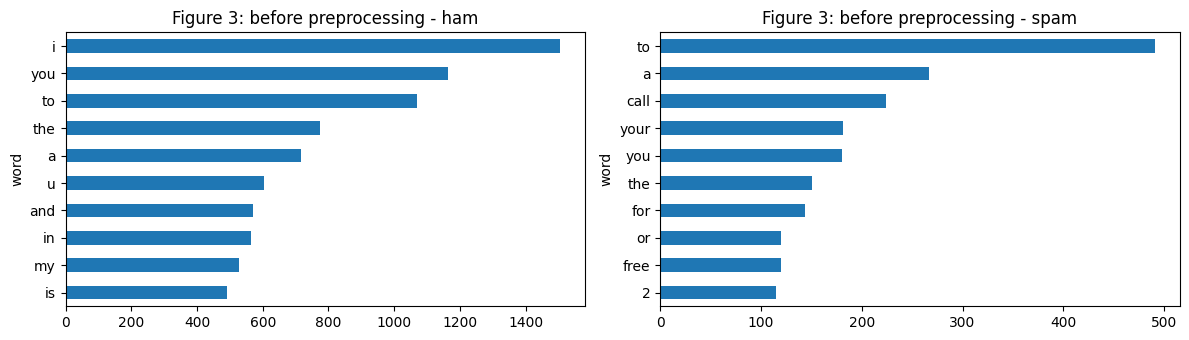

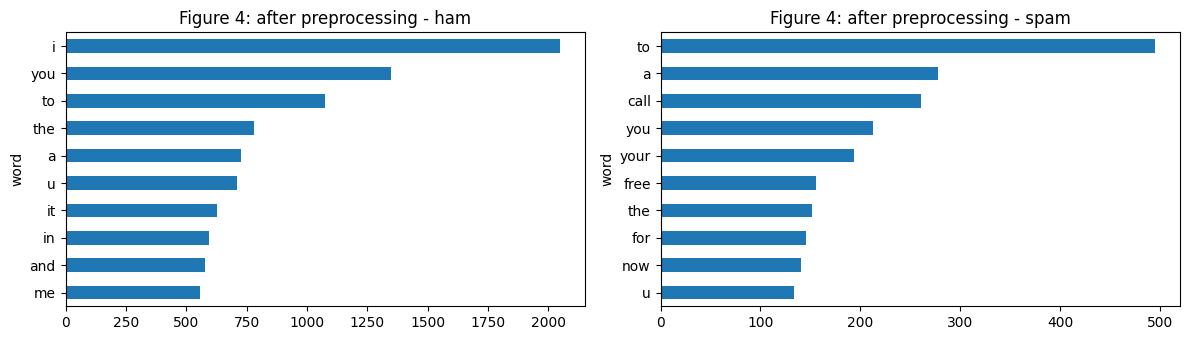

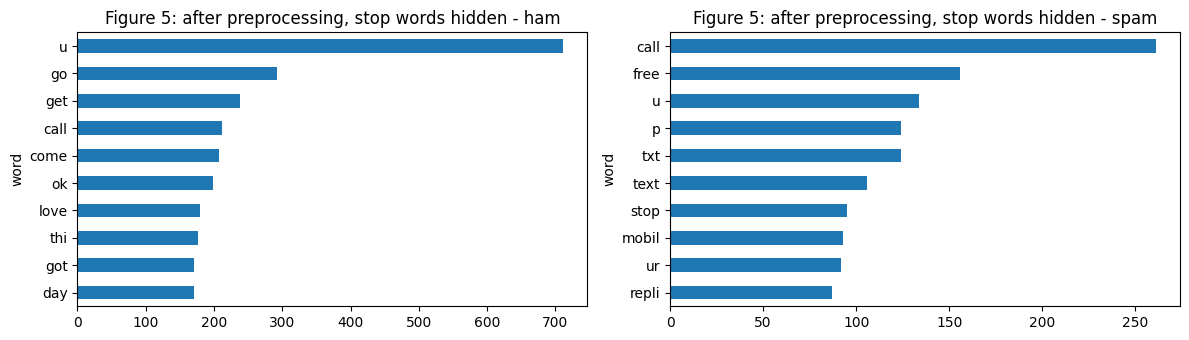

Figure 3: before preprocessing, both classes are led by common function words (i, you, to, the); only call, your and free hint at spam.
Figure 4: after preprocessing the lists look almost the same, because stop words were kept on purpose (the ablation shows removing them hurts) and the pipeline mostly removes digits and symbols.
Figure 5: with stop words hidden, spam is led by action words (call, free, txt, text, stop, reply) while ham is led by everyday chat words (go, get, come, ok, love, day).


In [6]:
def plot_top_words(texts_ham, texts_spam, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, texts, label in zip(axes, [texts_ham, texts_spam], ['ham', 'spam']):
        top = Counter(' '.join(texts).split()).most_common(10)
        pd.DataFrame(top, columns=['word', 'count']).plot.barh(x='word', y='count', ax=ax, legend=False)
        ax.invert_yaxis()
        ax.set_title(f'{title} - {label}')
    plt.tight_layout()
    plt.show()

is_ham, is_spam = train['label'] == 'ham', train['label'] == 'spam'
plot_top_words(train.loc[is_ham, 'message'].str.lower(), train.loc[is_spam, 'message'].str.lower(), 'Figure 3: before preprocessing')
plot_top_words(train.loc[is_ham, 'clean'], train.loc[is_spam, 'clean'], 'Figure 4: after preprocessing')
no_stop = train['clean'].apply(lambda text: ' '.join(w for w in text.split() if w not in stop_words))   # for viewing only
plot_top_words(no_stop[is_ham], no_stop[is_spam], 'Figure 5: after preprocessing, stop words hidden')
print('Figure 3: before preprocessing, both classes are led by common function words (i, you, to, the); only call, your and free hint at spam.')
print('Figure 4: after preprocessing the lists look almost the same, because stop words were kept on purpose (the ablation shows removing them hurts) and the pipeline mostly removes digits and symbols.')
print('Figure 5: with stop words hidden, spam is led by action words (call, free, txt, text, stop, reply) while ham is led by everyday chat words (go, get, come, ok, love, day).')

## 5. Text representations
**Title: Bag of Words, TF-IDF (unigram and uni+bigram) and average Word2Vec**

Models need numbers, not text. We build four representations. **Every vectoriser and the Word2Vec model are fitted on the training set only**; validation and test are only transformed, so nothing leaks.
- **BoW**: counts how often each word appears.
- **TF-IDF**: like BoW, but down-weights words that appear in almost every message. We try unigrams and unigrams + bigrams (word pairs such as "call now").
- **Average Word2Vec**: 100-number word vectors learned from our own training messages; a message is the average of its word vectors.

In [7]:
vectorizers = {
    'BoW': CountVectorizer(max_features=5000),
    'TF-IDF (unigram)': TfidfVectorizer(max_features=5000),
    'TF-IDF (uni+bigram)': TfidfVectorizer(max_features=5000, ngram_range=(1, 2))}

features = {}   # name -> (train, validation, test) matrices
for name, vec in vectorizers.items():
    features[name] = (vec.fit_transform(train['clean']), vec.transform(val['clean']), vec.transform(test['clean']))

# Word2Vec trained on the training messages only
w2v = Word2Vec([m.split() for m in train['clean']], vector_size=100, window=5, min_count=2, seed=SEED, workers=1)

def average_vector(texts):
    # average of the vectors of the known words (zeros if no known word)
    vectors = []
    for text in texts:
        known = [w2v.wv[w] for w in text.split() if w in w2v.wv]
        vectors.append(np.mean(known, axis=0) if known else np.zeros(100))
    return np.array(vectors)

features['Word2Vec (average)'] = (average_vector(train['clean']), average_vector(val['clean']), average_vector(test['clean']))
for name, (X_train, _, _) in features.items():
    print(name, 'train shape:', X_train.shape)

BoW train shape: (3901, 5000)
TF-IDF (unigram) train shape: (3901, 5000)
TF-IDF (uni+bigram) train shape: (3901, 5000)
Word2Vec (average) train shape: (3901, 100)


## 6. Classifiers and hyperparameter tuning
**Title: Baseline, Multinomial Naive Bayes and Logistic Regression**

- **Majority-class baseline:** always predicts "ham". Any real model must beat it.
- **Multinomial Naive Bayes (BoW and TF-IDF):** fast and a classic choice for word counts. It cannot use Word2Vec because Word2Vec values can be negative.
- **Logistic Regression (all four representations):** a strong linear model for sparse text and it also works on dense Word2Vec vectors.

For **each** model we try several values of one hyperparameter (`alpha` for Naive Bayes, `C` for Logistic Regression) and keep the one with the best **validation** macro-F1. The table is sorted by macro-F1, our main metric, because the classes are imbalanced. It also shows **spam recall** (the share of real spam that is caught), as promised in the proposal.

In [8]:
def scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Macro-Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'Macro-Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'Macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'Spam-Recall': recall_score(y_true, y_pred, pos_label='spam', zero_division=0)}   # share of spam caught

rows, models = [], {}   # models: row name -> (fitted model, representation name)

def tune(classifier, param, values, rep, **fixed):
    # try each value, keep the one with the best validation macro-F1
    X_train, X_val, _ = features[rep]
    best_f1, best_model, best_value = -1, None, None
    for value in values:
        model = classifier(**{param: value}, **fixed).fit(X_train, train['label'])
        f1 = f1_score(val['label'], model.predict(X_val), average='macro')
        if f1 > best_f1:
            best_f1, best_model, best_value = f1, model, value
    name = f'{rep} + {classifier.__name__} ({param}={best_value})'
    rows.append({'Model': name, **scores(val['label'], best_model.predict(X_val))})
    models[name] = (best_model, rep)
    return best_model

# majority-class baseline
baseline = DummyClassifier(strategy='most_frequent').fit(features['BoW'][0], train['label'])
rows.append({'Model': 'Majority-class baseline', **scores(val['label'], baseline.predict(features['BoW'][1]))})
models['Majority-class baseline'] = (baseline, 'BoW')

# Multinomial Naive Bayes: tune alpha
for rep in ['BoW', 'TF-IDF (unigram)', 'TF-IDF (uni+bigram)']:
    model = tune(MultinomialNB, 'alpha', [0.01, 0.1, 0.5, 1, 2], rep)
    if rep == 'BoW':
        nb_bow = model        # kept for the "informative words" step later

# Logistic Regression: tune C on all four representations
for rep in features:
    tune(LogisticRegression, 'C', [0.1, 1, 10, 100], rep, max_iter=1000, random_state=SEED)

val_table = pd.DataFrame(rows).sort_values('Macro-F1', ascending=False).reset_index(drop=True)
display(val_table.round(4))

,Model,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Spam-Recall
0,TF-IDF (uni+bigram) + LogisticRegression (C=100),0.9928,0.9919,0.9770,0.9843,0.9554
1,TF-IDF (unigram) + LogisticRegression (C=10),0.9916,0.9874,0.9763,0.9818,0.9554
2,BoW + LogisticRegression (C=10),0.9916,0.9912,0.9725,0.9816,0.9464
3,TF-IDF (uni+bigram) + MultinomialNB (alpha=0.01),0.9892,0.9785,0.9749,0.9767,0.9554
4,TF-IDF (unigram) + MultinomialNB (alpha=0.1),0.9868,0.9883,0.9547,0.9706,0.9107
5,BoW + MultinomialNB (alpha=2),0.9844,0.9751,0.9571,0.9658,0.9196
6,Word2Vec (average) + LogisticRegression (C=100),0.9593,0.9294,0.8897,0.9082,0.7946
7,Majority-class baseline,0.8660,0.4330,0.5000,0.4641,0.0000


## 7. Final test evaluation
**Title: Test set (used once) and confusion matrix of the best model**

The best model is the one with the highest **validation** macro-F1 (chosen above, before looking at the test set). Now, one time only, every model is scored on the test set. We also draw the confusion matrix of the best model.

,Model,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Spam-Recall
0,TF-IDF (uni+bigram) + LogisticRegression (C=100),0.9869,0.9883,0.9547,0.9706,0.9107
1,TF-IDF (unigram) + LogisticRegression (C=10),0.9857,0.9876,0.9502,0.9679,0.9018
2,BoW + LogisticRegression (C=10),0.9845,0.9869,0.9457,0.9650,0.8929
3,TF-IDF (unigram) + MultinomialNB (alpha=0.1),0.9821,0.9855,0.9368,0.9593,0.8750
4,TF-IDF (uni+bigram) + MultinomialNB (alpha=0.01),0.9797,0.9756,0.9354,0.9543,0.8750
5,BoW + MultinomialNB (alpha=2),0.9749,0.9607,0.9289,0.9440,0.8661
6,Word2Vec (average) + LogisticRegression (C=100),0.9534,0.9304,0.8599,0.8907,0.7321
7,Majority-class baseline,0.8662,0.4331,0.5000,0.4641,0.0000


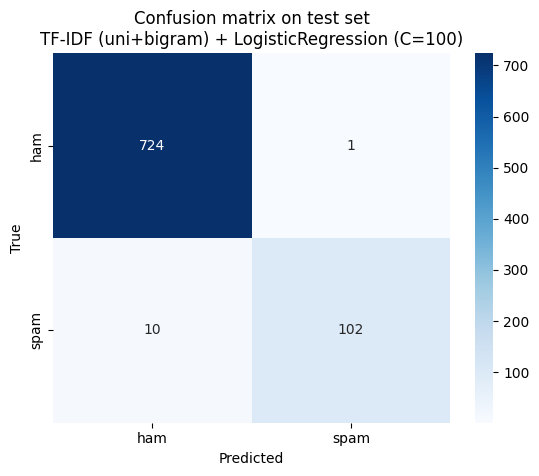

In [9]:
best_name = val_table.loc[0, 'Model']
test_table = pd.DataFrame([{'Model': name, **scores(test['label'], model.predict(features[rep][2]))}
                           for name, (model, rep) in models.items()])
test_table = test_table.sort_values('Macro-F1', ascending=False).reset_index(drop=True)
display(test_table.round(4))

best_model, best_rep = models[best_name]
test_pred = best_model.predict(features[best_rep][2])
sns.heatmap(confusion_matrix(test['label'], test_pred, labels=['ham', 'spam']), annot=True, fmt='d', cmap='Blues',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion matrix on test set\n' + best_name)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

## 8. Error analysis
**Title: Most informative words per class (Naive Bayes)**

For Naive Bayes, a word's strength is the log-probability ratio `log P(word | spam) - log P(word | ham)`. A large positive value means "typical of spam", a large negative value means "typical of ham". We use the tuned Naive Bayes + BoW model. Words appear in their preprocessed (stemmed) form.

In [10]:
words = np.array(vectorizers['BoW'].get_feature_names_out())
log_ratio = nb_bow.feature_log_prob_[1] - nb_bow.feature_log_prob_[0]   # classes_ = ['ham', 'spam']
order = np.argsort(log_ratio)
print('Top 10 SPAM words:', [f'{words[i]} ({log_ratio[i]:.1f})' for i in order[::-1][:10]])
print('Top 10 HAM words: ', [f'{words[i]} ({log_ratio[i]:.1f})' for i in order[:10]])

Top 10 SPAM words: ['claim (4.6)', 'prize (4.3)', 'tone (4.2)', 'cs (3.8)', 'pobox (3.8)', 'guarante (3.7)', 'ppm (3.7)', 'award (3.6)', 'servic (3.6)', 'rington (3.5)']
Top 10 HAM words:  ['he (-3.5)', 'lor (-3.1)', 'later (-3.1)', 'she (-3.0)', 'my (-3.0)', 'but (-2.9)', 'home (-2.8)', 'wat (-2.8)', 'da (-2.7)', 'way (-2.7)']


**Title: Collect misclassified test messages**

The best model makes only a few mistakes, so to inspect at least 20 messages we collect every test message that **at least one** of the 7 real models (all except the baseline) got wrong. `models_wrong` counts how many of those 7 failed on the message.

In [11]:
real_models = [name for name in models if name != 'Majority-class baseline']
wrong = pd.DataFrame({name: models[name][0].predict(features[models[name][1]][2]) != test['label'] for name in real_models})
errors = test[['message', 'label']].copy()
errors['models_wrong'] = wrong.sum(axis=1)
errors = errors[errors['models_wrong'] > 0].reset_index(drop=True)
print('Distinct misclassified test messages:', len(errors))
print('Misclassified by the best model:', int((test_pred != test['label']).sum()))

Distinct misclassified test messages: 49
Misclassified by the best model: 11


**Title: Group the errors into error types**

Each error is put in a group by simple rules (spam is the true label = a missed spam, ham is the true label = a false alarm). The groups are rough, but they let us count the kinds of mistakes and read the examples in each group.

In [12]:
def error_type(message, label):
    text = message.lower()
    has_number = bool(re.search(r'\d{5,}', text))                      # phone number or short code
    has_link = bool(re.search(r'www\.|http|\.com|£', text))            # link or money sign
    has_spam_word = bool(re.search(r'\b(call|free|win|won|prize|claim|txt|text|reply|stop|customer|service|callertune|contact|urgent)\b', text))
    if label == 'spam':      # a spam message the model called ham
        if not (has_number or has_link or has_spam_word):
            return 'Missed spam: reads like normal chat'
        if re.search(r'\b(u|ur|r|2|4)\b|2moro|4fil|wid|wiv', text):
            return 'Missed spam: SMS slang and misspellings'
        return 'Missed spam: other'
    if len(message.split()) <= 7:    # a ham message the model called spam
        return 'False alarm: very short chat message'
    if has_number or has_link or has_spam_word:
        return 'False alarm: genuine message with spam-like words'
    return 'False alarm: other'

errors['error type'] = [error_type(m, l) for m, l in zip(errors['message'], errors['label'])]
display(errors['error type'].value_counts())
pd.set_option('display.max_colwidth', 130)
display(errors.sort_values(['error type', 'models_wrong'], ascending=[True, False])[['error type', 'models_wrong', 'message']].reset_index(drop=True))

,count
error type,
Missed spam: other,16
Missed spam: SMS slang and misspellings,14
False alarm: very short chat message,8
False alarm: genuine message with spam-like words,6
Missed spam: reads like normal chat,4
False alarm: other,1


,error type,models_wrong,message
0,False alarm: genuine message with spam-like words,5,K..u also dont msg or reply to his msg..
1,False alarm: genuine message with spam-like words,2,As per your request 'Maangalyam (Alaipayuthe)' has been set as your callertune for all Callers. Press *9 to copy your friends ...
2,False alarm: genuine message with spam-like words,1,If india win or level series means this is record:)
3,False alarm: genuine message with spam-like words,1,"We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us"
4,False alarm: genuine message with spam-like words,1,HCL chennai requires FRESHERS for voice process.Excellent english needed.Salary upto &lt;#&gt; .Call Ms.Suman &lt;#&gt; for...
5,False alarm: genuine message with spam-like words,1,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press ...
6,False alarm: other,1,Can u get pic msgs to your phone?
7,False alarm: very short chat message,3,Match started.india &lt;#&gt; for 2
8,False alarm: very short chat message,1,Pls pls find out from aunt nike.
9,False alarm: very short chat message,1,Send to someone else :-)


## 9. Discussion and conclusions

**Why these representations and classifiers?** SMS spam is short English text where certain words ("free", "claim", "call", "txt") are strong signals, so word counts (BoW) and weighted word counts (TF-IDF) fit well. Bigrams add short phrases such as "call now". Naive Bayes is the classic fast baseline for word counts. Logistic Regression learns a weight per word and can also use dense Word2Vec vectors. Word2Vec was included to test dense meaning-based features, but with only about 3,900 short, slang-heavy training messages the vectors are weak.

**What the comparison shows (test set, macro-F1):**
- Best model: **TF-IDF (uni+bigram) + Logistic Regression**, macro-F1 0.9706, accuracy 0.9869. It made only 11 mistakes on 837 messages: 1 false alarm (ham called spam) and 10 missed spam. For a spam filter this is a good trade-off, since blocking a real message is usually worse than letting some spam through, though recall on the spam class (102 of 112) can still be improved.
- Logistic Regression beat Naive Bayes on every sparse representation (0.9650 to 0.9706 versus 0.9440 to 0.9593). Bigrams helped both classifiers slightly on validation.
- Average Word2Vec was clearly the weakest real model (0.8907). The majority-class baseline reaches 0.8662 accuracy but only 0.4641 macro-F1, which shows why accuracy alone is misleading on imbalanced data.

**Preprocessing ablation (validation macro-F1):** removing stop words lowered both models by about 0.01, because words like "you", "your" and "to" help separate spam from ham. Stemming helped Logistic Regression (+0.008) but slightly hurt Naive Bayes (-0.007), so the two best variants were almost tied (mean 0.9730 vs 0.9727) and we used stemming without stop-word removal.

**Informative words:** spam is signalled by claim, prize, award, guarantee, ringtone and PO-box/premium-rate terms (pobox, ppm), while ham is signalled by chatty words such as he, she, my, but, home, later and local slang (lor, wat, da).

**Error analysis:** 49 distinct test messages were missed by at least one model. Missed spam is the biggest group: 14 use SMS slang and misspellings (u, 2, 4, "4fil"), 4 read like normal chat (some, such as the tattoo and dartboard messages, may be mislabelled), and 16 have typical spam cues but still slipped through, including repeated "PRIVATE! Your 2003 Account Statement" templates and dating or adult-chat offers. False alarms are mostly very short chat messages (8) or genuine messages that use spam-like words such as "call", "customer service" or "callertune" (6).

**Limitations and next steps:** the dataset holds 403 duplicate messages, so a few test messages may also appear in training, which can make scores slightly optimistic. The error groups come from simple rules and are approximate. Future work could handle slang better (for example a slang dictionary), add features like "contains a phone number", and compare against transformer models in the final-term project.